# Задание 7. Обучение первой ML-модели (baseline)

Модель: Logistic Regression в одном `Pipeline` с признаками из задания 6. Все метрики считаются на **валидационной** выборке. Выборка test здесь не используется: она останется для однократной итоговой оценки в задании 8.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "manage.py").exists() else ROOT.parent
sys.path.insert(0, str(ROOT))

from ml.baseline import MODEL_PATH, compute_metrics, load_baseline, predict_sms, train_baseline
from ml.split import load_parts

pd.set_option("display.max_colwidth", 110)
COLUMNS = ["text_raw", "text_clean"]
parts = load_parts()
train, val = parts["train"], parts["val"]
print(f"train: {len(train)}, val: {len(val)}")

train: 3595, val: 771


## 1. Обучение на train

Параметры заданы в `ml/baseline.py`: `class_weight='balanced'`, `max_iter=1000`.

In [2]:
model = train_baseline(train)
model.named_steps["classifier"]

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

## 2. Предсказания и вероятности на валидации

In [3]:
val_pred = model.predict(val[COLUMNS])
val_proba = model.predict_proba(val[COLUMNS])[:, 1]
print("Первые 5 вероятностей мошенничества:", np.round(val_proba[:5], 3))

Первые 5 вероятностей мошенничества: [0.03  0.041 1.    0.012 0.022]


## 3. Метрики и Confusion Matrix

In [4]:
metrics = compute_metrics(val["label"], val_pred)
pd.Series({
    "Accuracy": metrics["accuracy"],
    "Precision (мошенничество)": metrics["precision"],
    "Recall (мошенничество)": metrics["recall"],
    "F1 (мошенничество)": metrics["f1"],
}).round(4)

Accuracy                     0.9870
Precision (мошенничество)    0.9560
Recall (мошенничество)       0.9355
F1 (мошенничество)           0.9457
dtype: float64

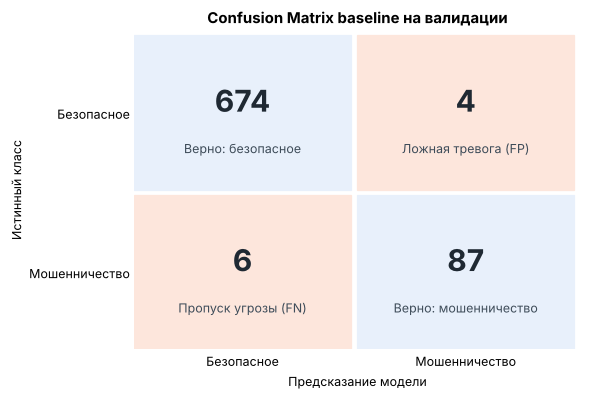

In [5]:
matrix = np.array([[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]])
captions = [["Верно: безопасное", "Ложная тревога (FP)"], ["Пропуск угрозы (FN)", "Верно: мошенничество"]]
colors = [["#e8f0fb", "#fde6dc"], ["#fde6dc", "#e8f0fb"]]

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for row in range(2):
    for col in range(2):
        ax.add_patch(plt.Rectangle((col, 1 - row), 0.97, 0.97, color=colors[row][col]))
        ax.text(col + 0.485, 1 - row + 0.56, str(matrix[row, col]), ha="center", va="center",
                fontsize=24, fontweight="bold", color="#1f2933")
        ax.text(col + 0.485, 1 - row + 0.26, captions[row][col], ha="center", va="center", fontsize=10, color="#3e4c59")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.485, 1.485], ["Безопасное", "Мошенничество"])
ax.set_yticks([1.485, 0.485], ["Безопасное", "Мошенничество"])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("Предсказание модели")
ax.set_ylabel("Истинный класс")
ax.set_title("Confusion Matrix baseline на валидации", fontweight="bold")
fig.savefig(ROOT / "docs" / "figures" / "06_confusion_matrix_baseline.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()

## 4. Разбор ошибок

Ложноотрицательных ошибок (FN) на валидации 6, показаны 5 с самой низкой вероятностью. Ложноположительных (FP) всего 4, поэтому пятой строкой идёт безопасное сообщение, ближе всех подошедшее к порогу 0,5. Оно не является ошибкой и добавлено, чтобы сохранить разбор из 10 примеров.

In [6]:
errors = val.assign(probability=val_proba.round(3))
errors["prediction"] = val_pred
false_negative = errors[(errors["label"] == 1) & (errors["prediction"] == 0)].sort_values("probability")
false_positive = errors[(errors["label"] == 0) & (errors["prediction"] == 1)].sort_values("probability", ascending=False)
near_threshold = errors[(errors["label"] == 0) & (errors["prediction"] == 0)].sort_values("probability", ascending=False)

print(f"Всего FN: {len(false_negative)}, всего FP: {len(false_positive)}")
review = pd.concat([
    false_negative.head(5).assign(kind="FN"),
    false_positive.head(5).assign(kind="FP"),
    near_threshold.head(10 - min(len(false_positive), 5) - 5).assign(kind="близко к порогу"),
])
review[["kind", "id", "probability", "text_raw"]]

Всего FN: 6, всего FP: 4


,kind,id,probability,text_raw
390,FN,2775,0.035,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to s...
201,FN,1431,0.083,For sale - arsenal dartboard. Good condition but no doubles or trebles!
236,FN,1639,0.146,"0A$NETWORKS allow companies to bill for SMS, so they are responsible for their ""suppliers"", just as a shop..."
388,FN,2771,0.245,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super w...
213,FN,1501,0.279,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Ps..."
428,FP,3095,0.705,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323
521,FP,3739,0.616,Plz note: if anyone calling from a mobile Co. &amp; asks u to type # &lt;#&gt; or # &lt;#&gt; . Do not do...
315,FP,2280,0.598,Hmm...Bad news...Hype park plaza $700 studio taken...Only left 2 bedrm-$900...
541,FP,3850,0.508,Can you plz tell me the ans. BSLVYL sent via fullonsms.com
168,близко к порогу,1201,0.493,NEFT Transaction with reference number &lt;#&gt; for Rs. &lt;DECIMAL&gt; has been credited to the benef...


| Вид | id | Комментарий |
|---|---|---|
| FN | 2775 | Шутка-рассылка без денег, ссылок и телефона. Сигналов для модели нет, а в тексте трудно увидеть спам |
| FN | 1431 | Объявление о продаже похоже на личное сообщение. Нет ни одного токена и слова давления |
| FN | 1639 | Рассуждение о биллинге без призыва к действию. Обычный слог, запись `0a$networks` модели незнакома |
| FN | 2771 | Реклама с розыгрышем: есть `winner`, но нет суммы и телефона. Это реклама, а не мошенничество |
| FN | 1501 | Платная подписка на гороскоп, написанная сленгом (`2day`, `ur`, `r`). Нет суммы, телефона и ссылки |
| FP | 3095 | Сообщение целиком состоит из ссылки. Остался только токен `<url>`, а он редок в ham (0,3%) |
| FP | 3739 | Предупреждение о мошенниках: в тексте призывы и лексика самой схемы, текст длинный |
| FP | 2280 | Две суммы подряд дают два токена `<money>`, в ham это редкость |
| FP | 3850 | Подпись сервиса рассылки `fullonsms.com` превратилась в `<url>` |
| близко к порогу | 1201 | Банковское уведомление о зачислении, модель поставила 0,493, ниже порога. Это верный ответ, но запас мал |

**Причины.**

- **Пропуски.** Пять показанных FN не содержат ни ссылки, ни суммы, ни телефона. Это реклама и подписки, что подтверждает ограничение из паспорта набора: спам не равен мошенничеству.
- **Ложные тревоги.** Все 4 FP связаны с признаками, редкими в ham: `<url>`, `<money>` или длинный текст с призывами. Это ожидалось по выводам EDA.
- **Гипотеза о `<phone>`.** На валидации её проверить нельзя, потому что телефонов в ham почти нет. Ручная проверка в разделе 6 показывает, что проблема реальна.

## 5. Сохранение и загрузка pipeline

In [7]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_PATH, compress=3)
print(f"Сохранено: {MODEL_PATH.relative_to(ROOT)}, {MODEL_PATH.stat().st_size / 1024:.0f} КБ")

Сохранено: ml/artifacts/sms_baseline.joblib, 460 КБ


In [8]:
loaded = joblib.load(MODEL_PATH)
loaded_proba = loaded.predict_proba(val[COLUMNS])[:, 1]

print("Предсказания совпадают:", bool((loaded.predict(val[COLUMNS]) == val_pred).all()))
print("Вероятности совпадают:", bool(np.allclose(loaded_proba, val_proba)))

Предсказания совпадают: True
Вероятности совпадают: True


## 6. Функция `predict_sms` на новых текстах

Эти тексты придуманы для проверки, их нет в наборе. Модель обучена только на английских SMS, поэтому результат для русского текста **ненадёжен** и показан лишь для демонстрации этого ограничения. Качество на русском и казахском будет измерено в задании 8.

In [9]:
new_texts = [
    "Hey, are we still meeting for lunch tomorrow?",
    "Your order #4821 has been shipped and will arrive tomorrow.",
    "URGENT! Your bank account has been suspended. Verify now at http://secure-bank-verify.example/login",
    "Congratulations! You won a 1000 pound prize. Call 09061701461 to claim",
    "Hi, it's Anna, my new number is +7 000 000 00 00",
    "Ваша карта заблокирована! Срочно подтвердите данные: http://card-unlock.example",
    "Привет! Встречаемся завтра в 18:00 у входа в библиотеку.",
]
load_baseline.cache_clear()
pd.DataFrame([{"текст": text, **predict_sms(text)} for text in new_texts]).round({"probability": 3})

,текст,label,probability
0,"Hey, are we still meeting for lunch tomorrow?",0,0.018
1,Your order #4821 has been shipped and will arrive tomorrow.,0,0.119
2,URGENT! Your bank account has been suspended. Verify now at http://secure-bank-verify.example/login,1,0.966
3,Congratulations! You won a 1000 pound prize. Call 09061701461 to claim,1,1.000
4,"Hi, it's Anna, my new number is +7 000 000 00 00",1,0.911
5,Ваша карта заблокирована! Срочно подтвердите данные: http://card-unlock.example,1,0.983
6,Привет! Встречаемся завтра в 18:00 у входа в библиотеку.,0,0.410


## 7. Выводы

- **Качество на валидации:** Accuracy 0,987, Precision 0,956, Recall 0,935, F1 0,946 для класса «мошенничество». Из 93 мошеннических сообщений найдено 87, ложных тревог 4 из 678 безопасных.
- **Полный цикл отработан:** модель обучена, оценена, сохранена в файл и загружена обратно. Предсказания совпадают до и после загрузки.
- **Подтверждён недостаток:** безобидное сообщение с номером телефона получает вероятность 0,911. Модель переоценивает `<phone>`, потому что в ham этого набора телефонов почти нет. Высокие метрики этого не показывают, так как проблема находится вне распределения набора.
- **Русский текст ненадёжен:** безопасное сообщение на русском получило 0,410, хотя похожее на английском получает около 0,02. Модель не знает русских слов и опирается в основном на ручные признаки.

**Что дальше (задание 8):** сравнить алгоритмы и варианты признаков, подобрать порог на валидации, проверить модель на собственном русско-казахском наборе. Там же стоит сравнить модель с признаком `<phone>` и без него.